# ScaleHyperprior in One Training Step (beginner version)

In this short notebook we will:

1. **Read one DIV2K image** that already exists in `data/DIV2K/DIV2K_train_HR/`.
2. **Show it** and cut a small 256×256 piece (a *crop*) from it.
3. **Meet the ScaleHyperprior model** from CompressAI — a neural network that compresses images.
4. Do **exactly one training step** and explain every line.
5. Use the model to **really compress** the crop into bytes and decompress it.

> ⚠️ One training step is only to *learn the mechanics*. Real training needs hundreds of thousands of steps,
> so do not expect the image quality to change in a visible way.

Run the cells **from top to bottom** with **Shift+Enter**.

## Step 1 — Prepare Python

The first cell is a small Windows fix: it tells Python where the Conda DLL files are, so that PyTorch
can load its GPU libraries without crashing. You do not need to understand it — just run it first.

Now we import the libraries we need:

* `PIL.Image` reads image files, `matplotlib` shows them.
* `torch` is PyTorch, the deep-learning library.
* `compressai` gives us the ScaleHyperprior model and its loss function.

In [18]:
import os, sys
from pathlib import Path

_conda_dll_handles = []
_conda_bin = Path(sys.prefix) / 'Library' / 'bin'
if sys.platform == 'win32' and _conda_bin.is_dir():
    os.environ['PATH'] = str(_conda_bin) + os.pathsep + os.environ.get('PATH', '')
    _conda_dll_handles.append(os.add_dll_directory(str(_conda_bin)))

import math
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

import compressai
from compressai.zoo import bmshj2018_hyperprior
from compressai.losses import RateDistortionLoss

torch.manual_seed(0) # Set the random seed for reproducibility

print('PyTorch   :', torch.__version__)
print('CompressAI:', compressai.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch   : 2.13.0
CompressAI: 1.2.8
PyTorch: 2.13.0
CUDA available: True
PyTorch CUDA version: 13.0
GPU: Quadro T1000 with Max-Q Design


In [19]:
import torch

DEVICE = "cpu"  # Choose "cpu" or "cuda" (NVIDIA GPU)

if DEVICE not in ("cpu", "cuda"):
    raise ValueError('DEVICE must be "cpu" or "cuda".')

if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError(
        "GPU requested, but CUDA is unavailable. "
        "Check your NVIDIA driver and PyTorch installation, "
        'or set DEVICE = "cpu".'
    )

device = torch.device(DEVICE)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

Device: cpu


## Step 2 — Read one DIV2K image

DIV2K is a dataset of high-quality 2K photos. We pick **one** image that is already on disk.
The code walks up from the current folder until it finds the folder that contains `data/`.

In [20]:
project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data').is_dir()),
    None
)
if project_root is None:
    raise FileNotFoundError("Could not find a parent folder containing 'data/'.")

image_path = project_root / 'data' / 'DIV2K' / 'DIV2K_train_HR' / '0002.png'
image = Image.open(image_path).convert('RGB')

print('File      :', image_path.name)
print('Size (W×H):', image.size)
print('Mode      :', image.mode)


File      : 0002.png
Size (W×H): (2040, 1848)
Mode      : RGB


Let us look at the full image.

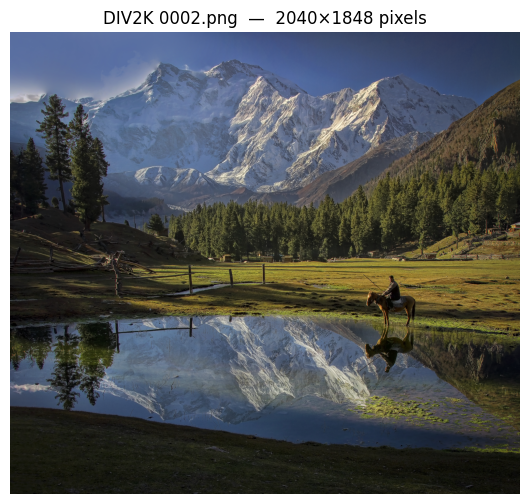

In [21]:
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title(f'DIV2K {image_path.name}  —  {image.size[0]}×{image.size[1]} pixels')
plt.axis('off')
plt.show()

## Step 3 — Cut a 256×256 crop and turn it into a tensor

The full image is large. Training on it would be slow, so — exactly like real training on DIV2K —
we use a **256×256 crop**. We take it from the **center** so you always get the same result.

A neural network does not read pictures; it reads **tensors** (arrays of numbers).
We convert the pixels from `0…255` to `0.0…1.0` and arrange them as **(batch, channels, height, width)**.

In [22]:
crop_size = 256
W, H = image.size
left, top = (W - crop_size) // 2, (H - crop_size) // 2
crop = image.crop((left, top, left + crop_size, top + crop_size))

pixels = np.asarray(crop, dtype=np.float32) / 255.0      # (256, 256, 3), values 0..1
x = torch.from_numpy(pixels).permute(2, 0, 1).unsqueeze(0).to(device)
print('Tensor shape:', tuple(x.shape), '-> (batch, channels, height, width)')
print('Value range :', round(x.min().item(), 3), 'to', round(x.max().item(), 3))

Tensor shape: (1, 3, 256, 256) -> (batch, channels, height, width)
Value range : 0.0 to 1.0


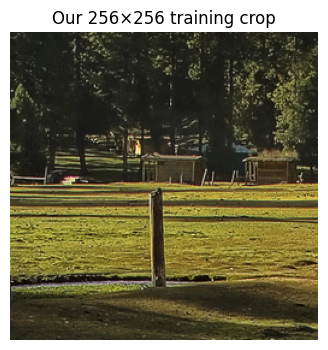

In [23]:
plt.figure(figsize=(4, 4))
plt.imshow(crop)
plt.title('Our 256×256 training crop')
plt.axis('off')
plt.show()

## Step 4 — Meet ScaleHyperprior

ScaleHyperprior (Ballé et al., 2018) is made of four small networks:

| Part | Name in code | What it does |
|---|---|---|
| Encoder | `g_a` | image `x` → compact features **`y`** |
| Hyper-encoder | `h_a` | `y` → tiny "side information" **`z`** |
| Hyper-decoder | `h_s` | `z` → **`scales`**: how spread out each value of `y` is |
| Decoder | `g_s` | `y` → reconstructed image **`x_hat`** |

The `scales` help the entropy coder: if it knows how spread out a value is, it can store it with fewer bits.

**Main parameters**

* `quality` (1–8): which pretrained model to load. Low = small file, high = better image.
* `N`: number of channels inside the networks (128 for quality 1–5).
* `M`: number of channels of `y` (192 for quality 1–5).
* `metric='mse'`: the model was trained to minimise mean squared error.
* `pretrained=True`: download already-trained weights so we start from a good model.

### Scale Hyperprior architecture

```text
Input image
3 × H × W
    ↓
Main encoder g_a
Intermediate layers use N channels
    ↓
Main latent y
M × H/16 × W/16
    ├───────────────────────────────┐
    ↓                               ↓
Hyper-encoder h_a               Quantization
    ↓                               ↓
Hyperlatent z                  Main latent y_hat
N channels                          ↓
    ↓                          Main decoder g_s
Quantization                        ↓
    ↓                          Reconstructed image
Hyper-decoder h_s
    ↓
Predicted scales for coding y_hat
```


### What the model parameters control

There are two meanings of *parameters* here: settings passed when creating the model, and the learned tensor values stored inside it.

| Parameter | Value here | Effect on the model |
|---|---:|---|
| `quality` | `3` | Selects the pretrained model variant. Higher quality variants generally target better reconstructions at a higher bitrate, and can use a different model capacity. |
| `metric` | `'mse'` | Selects mean squared error as the distortion measure associated with this model variant. Squared pixel errors are penalized more strongly when they are large. |
| `pretrained` | `True` | Loads learned weights for the selected variant. With `False`, the model starts from random weights and needs training before it can compress images well. |
| `N` | `128` | Number of feature channels used by internal and hyperprior layers. More channels increase representational capacity, computation, and parameter count. |
| `M` | `192` | Number of channels in the main latent `y`. This controls how many learned features represent the image; changing it affects compression capacity, computation, and model size. |

The learned **main parameters** are the weights and biases in the encoder, decoder, hyper-encoder, and hyper-decoder (`g_a`, `g_s`, `h_a`, and `h_s`). They determine which image features are represented in `y`, how `z` predicts the distribution scales for coding `y`, and how `y_hat` is turned back into an image. The rate-distortion loss updates these parameters.

The entropy bottleneck also has learned `quantiles`. They help define the probability model used to encode the hyperlatent `z`; this notebook updates them separately with the auxiliary loss and optimizer. The predicted scales and the quantized latents are values computed during a forward pass, not trainable parameters themselves.


![alt text](5985551984209105492.jpg)

In [24]:
model = bmshj2018_hyperprior(
    quality=3,
    metric='mse', 
    pretrained=True).to(device) 

n_params = sum(p.numel() for p in model.parameters())
print('N (inner channels):', model.N)
print('M (channels of y) :', model.M)
print(f'Parameters        : {n_params:,}')

N (inner channels): 128
M (channels of y) : 192
Parameters        : 5,075,843


check latent y and z shapes to ensure they match the expected dimensions after the forward pass.

In [25]:
with torch.no_grad():
    y = model.g_a(x)              # encoder
    z = model.h_a(torch.abs(y))   # hyper-encoder
    scales = model.h_s(z)         # hyper-decoder

print('x      :', tuple(x.shape)) # input image shape
print('y      :', tuple(y.shape), '  <- 16× smaller in height and width')
print('z      :', tuple(z.shape), '    <- 4× smaller again')
print('scales :', tuple(scales.shape), '  <- one scale for every value of y')

x      : (1, 3, 256, 256)
y      : (1, 192, 16, 16)   <- 16× smaller in height and width
z      : (1, 128, 4, 4)     <- 4× smaller again
scales : (1, 192, 16, 16)   <- one scale for every value of y


## Step 5 — The loss: rate + distortion

Compression is a trade-off between two things:

* **Rate** (`bpp_loss`): estimated *bits per pixel* → how big the file is.
* **Distortion** (`mse_loss`): mean squared error → how different the reconstruction is.

CompressAI combines them:

$$\text{loss} = \lambda \cdot 255^2 \cdot \text{MSE} + \text{bpp}$$

`λ` (lambda) decides what matters more. Quality 3 was trained with `λ = 0.0067`, so we use the same value.

In [26]:
criterion = RateDistortionLoss(lmbda=0.0067)

model.eval() # set the model to evaluation mode
with torch.no_grad():
    losses_before = criterion(model(x), x)

for name in ['loss', 'bpp_loss', 'mse_loss']:
    print(f'{name:9s} before training: {losses_before[name].item():.5f}')

loss      before training: 1.41322
bpp_loss  before training: 0.59454
mse_loss  before training: 0.00188


## Step 6 — Two optimizers

An **optimizer** changes the model weights to make the loss smaller.
ScaleHyperprior needs **two**:

1. **Main optimizer** — updates the normal network weights using the rate-distortion loss.
2. **Auxiliary optimizer** — updates only the `quantiles` of the entropy model of `z`.
   These are needed so the real entropy coder works correctly; they have their own small `aux_loss`.

We split the parameters by name and give each group to an Adam optimizer.

The **learning rate** (`lr`) is the step size. Our model is already trained, so we use a very small value (`1e-5`): a big step would push the good weights away from where they are.

In [27]:
main_params = [p for n, p in model.named_parameters() if not n.endswith('.quantiles')]
aux_params  = [p for n, p in model.named_parameters() if n.endswith('.quantiles')]

optimizer     = torch.optim.Adam(main_params, lr=1e-5)
aux_optimizer = torch.optim.Adam(aux_params,  lr=1e-3)

print('Main parameter tensors:', len(main_params))
print('Aux  parameter tensors:', len(aux_params))

Main parameter tensors: 54
Aux  parameter tensors: 1


## Step 7 — ONE training step

A training step always has the same recipe. We split it into small cells.

### 7a. Clear old gradients and switch to training mode
Gradients add up in PyTorch, so we reset them to zero first.
`model.train()` turns on training behaviour (here: noise is added instead of rounding, so we can compute gradients).

In [28]:
model.train() # Set the model to training mode
optimizer.zero_grad() # Clear the gradients of the optimizer
aux_optimizer.zero_grad() # Clear the gradients of the auxiliary optimizer

### 7b. Forward pass
The crop goes through the model. We get the reconstruction `x_hat` and the *likelihoods* used to estimate the bits.
Then we compute the loss.

In [29]:
output = model(x)
losses = criterion(output, x)

print('Output keys :', list(output.keys()))
print('x_hat shape :', tuple(output['x_hat'].shape))
print(f"loss = {losses['loss'].item():.5f}   bpp = {losses['bpp_loss'].item():.4f}   mse = {losses['mse_loss'].item():.6f}")

Output keys : ['x_hat', 'likelihoods']
x_hat shape : (1, 3, 256, 256)
loss = 1.45354   bpp = 0.7120   mse = 0.001702


### 7c. Backward pass
`backward()` computes, for every weight, how the loss would change if that weight changed (the **gradient**).
We also *clip* very large gradients so one step cannot break the model.

In [30]:
losses['loss'].backward()

### 7d. Update the main weights
`optimizer.step()` moves each weight a little bit in the direction that lowers the loss.
We check one weight to see that it really changed.

In [31]:
w = model.g_a[0].weight # Get the weight of the first encoder layer
w_before = w.detach().clone() # Clone the weight before the optimizer step to compare changes later

optimizer.step()

print(f'Largest change in the first encoder layer: {(w.detach() - w_before).abs().max().item():.2e}')

Largest change in the first encoder layer: 1.00e-05


### 7e. Update the auxiliary parameters
Same recipe for the small auxiliary loss: compute it, `backward()`, `step()`.

In [32]:
aux_loss = model.aux_loss() # Compute the auxiliary loss
aux_loss.backward() # Backpropagate the auxiliary loss
aux_optimizer.step() # Update the auxiliary optimizer
print(f'aux_loss = {aux_loss.item():.3f}') # Print the auxiliary loss
print('✅ One training step finished.')

aux_loss = 233.172
✅ One training step finished.


### 7f. Did the loss change?
We measure the loss again on the same crop, in evaluation mode.
The difference will be **very small**, and it can even go slightly **up** instead of down:

* one step on one crop is far too little to learn anything real;
* during training the model adds random noise (7a), so the loss we optimised is not exactly the loss we measure here.

This is normal — real training only improves the loss *on average* over many steps.

In [33]:
model.eval() # Set the model to evaluation mode
with torch.no_grad(): # Disable gradient computation for evaluation
    losses_after = criterion(model(x), x) # Compute the losses after the training step

for name in ['loss', 'bpp_loss', 'mse_loss']: # Iterate over the different loss components
    b, a = losses_before[name].item(), losses_after[name].item()
    print(f'{name:9s} before: {b:.5f}   after: {a:.5f}   change: {a - b:+.5f}') # Print the before and after values along with the change

loss      before: 1.41322   after: 1.40696   change: -0.00626
bpp_loss  before: 0.59454   after: 0.59245   change: -0.00210
mse_loss  before: 0.00188   after: 0.00187   change: -0.00001


## Step 8 — Real compression

During training the bits were only *estimated*. Now we create a **real bitstream**:

1. `model.update(force=True)` rebuilds the probability tables after training.
2. `model.compress(x)` → bytes for `y` and bytes for `z`.
3. `model.decompress(...)` → image from those bytes.

**bpp** (bits per pixel) = total bits ÷ number of pixels. An uncompressed RGB image uses 24 bpp.

In [34]:
model.update(force=True) # Force the model to update its internal state

with torch.no_grad(): # Disable gradient computation for compression
    compressed = model.compress(x) # Compress the input image

y_bytes = sum(len(s) for s in compressed['strings'][0]) # Compute the number of bytes for y
z_bytes = sum(len(s) for s in compressed['strings'][1]) # Compute the number of bytes for z
bpp = 8 * (y_bytes + z_bytes) / (crop_size * crop_size) # Compute the bits per pixel (bpp)

print(f'y bytes: {y_bytes}   z bytes: {z_bytes}   total: {y_bytes + z_bytes} bytes')
print(f'Real bpp: {bpp:.4f}   (uncompressed: 24 bpp, {crop_size * crop_size * 3} bytes)')

y bytes: 4788   z bytes: 92   total: 4880 bytes
Real bpp: 0.5957   (uncompressed: 24 bpp, 196608 bytes)


Now decode the bytes and measure quality with **PSNR** (Peak Signal-to-Noise Ratio, in dB — higher is better):

$$\text{PSNR} = -10 \log_{10}(\text{MSE})$$

In [35]:
with torch.no_grad():
    x_hat = model.decompress(compressed['strings'], compressed['shape'])['x_hat'].clamp(0, 1)

mse = torch.mean((x - x_hat) ** 2).item()
psnr = -10 * math.log10(mse)
print(f'MSE : {mse:.6f}')
print(f'PSNR: {psnr:.2f} dB')

MSE : 0.001869
PSNR: 27.28 dB


Finally, compare the original crop with the decoded one.

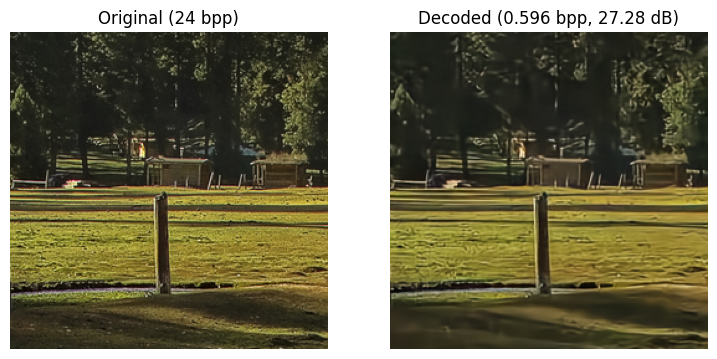

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(crop)
axes[0].set_title('Original (24 bpp)')
axes[1].imshow(x_hat[0].permute(1, 2, 0).cpu().numpy())
axes[1].set_title(f'Decoded ({bpp:.3f} bpp, {psnr:.2f} dB)')
for ax in axes:
    ax.axis('off')
plt.show()